In [1]:
!nvcc --version
!nvidia-smi

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Fri_Feb_21_20:23:50_PST_2025
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0
Sat Jul 18 20:33:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8       

In [2]:
!git clone https://github.com/Medha5510/WildFire-Prediction.git
%cd WildFire-Prediction

Cloning into 'WildFire-Prediction'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 9 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 8.24 KiB | 2.06 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/WildFire-Prediction


In [4]:
!nvcc cuda_sim.cu -o cuda_sim -O2

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
cuda_sim.cu(92): warning #1650-D: result of call is not used
      system("mkdir -p frames_cuda");
      ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

cuda_sim.cu(92): warning #1650-D: result of call is not used
      system("mkdir -p frames_cuda");
      ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

cuda_sim.cu: In function ‘int main(int, char**)’:
cuda_sim.cu:92:7: warning: ignoring return value of ‘int system(const char*)’ declared with attribute ‘warn_unused_result’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-result-Wunused-result]8;;]
   92 |     system("mkdir -p frames_cuda");
      |     ~~^~~~~~~~~~~~~~~~~~~~~~~~


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!ls "/content/drive/MyDrive/archive (3)/"

next_day_wildfire_spread_eval_00.tfrecord
next_day_wildfire_spread_eval_01.tfrecord
next_day_wildfire_spread_test_00.tfrecord
next_day_wildfire_spread_test_01.tfrecord
next_day_wildfire_spread_train_00.tfrecord
next_day_wildfire_spread_train_01.tfrecord
next_day_wildfire_spread_train_02.tfrecord
next_day_wildfire_spread_train_03.tfrecord
next_day_wildfire_spread_train_04.tfrecord
next_day_wildfire_spread_train_05.tfrecord
next_day_wildfire_spread_train_06.tfrecord
next_day_wildfire_spread_train_07.tfrecord
next_day_wildfire_spread_train_08.tfrecord
next_day_wildfire_spread_train_09.tfrecord
next_day_wildfire_spread_train_10.tfrecord
next_day_wildfire_spread_train_11.tfrecord
next_day_wildfire_spread_train_12.tfrecord
next_day_wildfire_spread_train_13.tfrecord
next_day_wildfire_spread_train_14.tfrecord


In [3]:
import glob

data_dir = "/content/drive/MyDrive/archive (3)"
train_files = glob.glob(f"{data_dir}/next_day_wildfire_spread_train_*.tfrecord")
print(len(train_files), "train files found")
print(train_files[0])

15 train files found
/content/drive/MyDrive/archive (3)/next_day_wildfire_spread_train_00.tfrecord


In [4]:
import tensorflow as tf

raw_dataset = tf.data.TFRecordDataset([train_files[0]])

for raw_record in raw_dataset.take(1):
    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())
    for key, feature in example.features.feature.items():
        n_values = len(feature.float_list.value)
        print(key, "->", n_values, "values")

NDVI -> 4096 values
tmmn -> 4096 values
elevation -> 4096 values
population -> 4096 values
FireMask -> 4096 values
vs -> 4096 values
pdsi -> 4096 values
pr -> 4096 values
tmmx -> 4096 values
sph -> 4096 values
th -> 4096 values
PrevFireMask -> 4096 values
erc -> 4096 values


In [5]:
import numpy as np

SIZE = 64  # replace if Step 2 showed a different grid size
FEATURES = ['elevation', 'NDVI', 'th', 'vs', 'PrevFireMask', 'FireMask']  # replace with real keys from Step 2

def parse(example_proto):
    feat = {f: tf.io.FixedLenFeature([SIZE, SIZE], tf.float32) for f in FEATURES}
    return tf.io.parse_single_example(example_proto, feat)

parsed_dataset = raw_dataset.map(parse)

for sample in parsed_dataset.take(1):
    for name, tensor in sample.items():
        arr = tensor.numpy().astype(np.float32)
        arr.tofile(f"/content/{name}.bin")
        print("saved", name, arr.shape)

saved FireMask (64, 64)
saved NDVI (64, 64)
saved PrevFireMask (64, 64)
saved elevation (64, 64)
saved th (64, 64)
saved vs (64, 64)


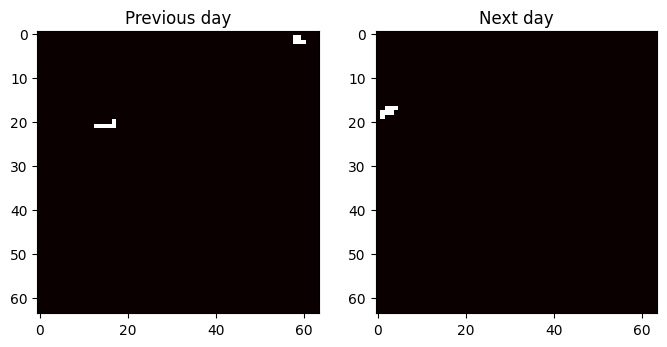

In [6]:
import matplotlib.pyplot as plt

prev = np.fromfile("/content/PrevFireMask.bin", dtype=np.float32).reshape(SIZE, SIZE)
next_ = np.fromfile("/content/FireMask.bin", dtype=np.float32).reshape(SIZE, SIZE)

fig, ax = plt.subplots(1, 2, figsize=(8,4))
ax[0].imshow(prev, cmap="hot"); ax[0].set_title("Previous day")
ax[1].imshow(next_, cmap="hot"); ax[1].set_title("Next day")
plt.show()

In [7]:
fire_pixels = (next_ == 1)   # not next_ > 0.5 — avoid accidentally counting -1 as "true"

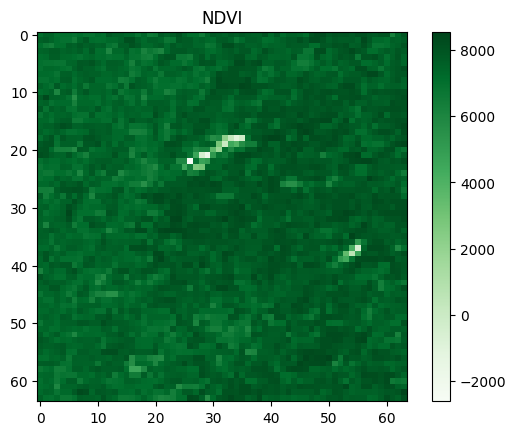

In [11]:
FEATURES = ['elevation', 'NDVI', 'PrevFireMask', 'FireMask']  # add/remove based on what Step 2 (unique keys) showed you

for sample in parsed_dataset.take(1):
    for name, tensor in sample.items():
        arr = tensor.numpy().astype(np.float32)
        arr.tofile(f"/content/{name}.bin")

# sanity check NDVI looks like terrain/vegetation, not a fire blob
ndvi = np.fromfile("/content/NDVI.bin", dtype=np.float32).reshape(SIZE, SIZE)
plt.imshow(ndvi, cmap="Greens"); plt.title("NDVI"); plt.colorbar(); plt.show()

In [12]:
!git clone https://github.com/Medha5510/WildFire-Prediction.git
!cp /content/NDVI.bin /content/PrevFireMask.bin /content/FireMask.bin /content/WildFire-Prediction/
%cd /content/WildFire-Prediction

Cloning into 'WildFire-Prediction'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 9 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 8.24 KiB | 8.24 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/WildFire-Prediction


In [15]:
!make serial
!./serial 64 64 50 NDVI.bin PrevFireMask.bin

g++ -O2 -std=c++17 serial.cpp -o serial
serial.cpp: In function ‘int main(int, char**)’:
serial.cpp:115:11: warning: ignoring return value of ‘int system(const char*)’ declared with attribute ‘warn_unused_result’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-result-Wunused-result]8;;]
  115 |     system("mkdir -p frames_serial");
      |     ~~~~~~^~~~~~~~~~~~~~~~~~~~~~~~~~
[serial] grid=64x64 steps=50 time=2.89 ms burning=34 burnt=4056


In [16]:
pred = np.fromfile("predicted_mask.bin", dtype=np.float32).reshape(64, 64)
real = np.fromfile("FireMask.bin", dtype=np.float32).reshape(64, 64)

pred_bin = pred > 0
real_bin = real == 1

inter = np.logical_and(pred_bin, real_bin).sum()
union = np.logical_or(pred_bin, real_bin).sum()
print("IoU:", inter / union if union > 0 else 0)

IoU: 0.0017114914425427872


In [17]:
print("predicted fire pixels:", pred_bin.sum())
print("real fire pixels:", real_bin.sum())
print("intersection:", inter)
print("union:", union)

predicted fire pixels: 4090
real fire pixels: 7
intersection: 7
union: 4090


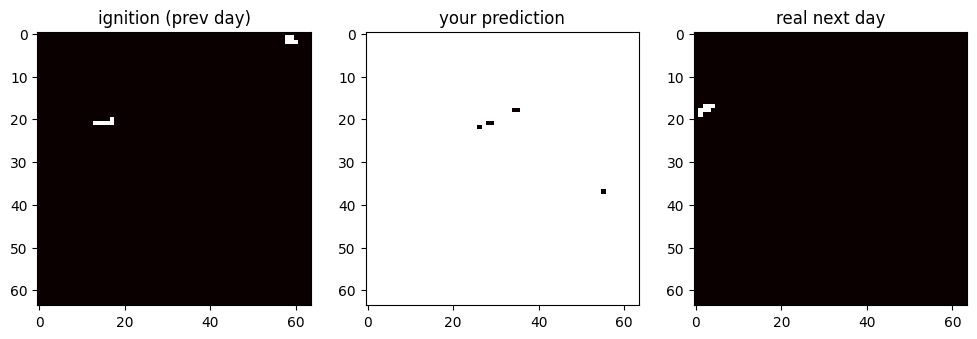

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))
ax[0].imshow(prev.reshape(64,64), cmap="hot"); ax[0].set_title("ignition (prev day)")
ax[1].imshow(pred_bin.reshape(64,64), cmap="hot"); ax[1].set_title("your prediction")
ax[2].imshow(real_bin.reshape(64,64), cmap="hot"); ax[2].set_title("real next day")
plt.show()

In [20]:
print("predicted fire pixels:", pred_bin.sum(), "out of", pred_bin.size)
print("real fire pixels:", real_bin.sum())

predicted fire pixels: 4090 out of 4096
real fire pixels: 7


In [22]:
!pwd
!ls serial

/content/WildFire-Prediction
serial


In [23]:
import subprocess

for steps, base_rate in [(5, 0.1), (10, 0.1), (5, 0.2), (10, 0.05)]:
    subprocess.run(["./serial", "64", "64", str(steps), "NDVI.bin", "PrevFireMask.bin", str(base_rate)])
    pred = np.fromfile("predicted_mask.bin", dtype=np.float32).reshape(64,64) > 0
    iou = np.logical_and(pred, real_bin).sum() / max(np.logical_or(pred, real_bin).sum(), 1)
    print(f"steps={steps} base_rate={base_rate} -> predicted={pred.sum()} IoU={iou:.4f}")

steps=5 base_rate=0.1 -> predicted=264 IoU=0.0000
steps=10 base_rate=0.1 -> predicted=753 IoU=0.0040
steps=5 base_rate=0.2 -> predicted=264 IoU=0.0000
steps=10 base_rate=0.05 -> predicted=753 IoU=0.0040


In [24]:
!rm -f serial
!make serial
!ls -la serial

g++ -O2 -std=c++17 serial.cpp -o serial
serial.cpp: In function ‘int main(int, char**)’:
serial.cpp:115:11: warning: ignoring return value of ‘int system(const char*)’ declared with attribute ‘warn_unused_result’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-result-Wunused-result]8;;]
  115 |     system("mkdir -p frames_serial");
      |     ~~~~~~^~~~~~~~~~~~~~~~~~~~~~~~~~
-rwxr-xr-x 1 root root 22048 Jul 21 12:02 serial


In [25]:
!./serial 64 64 5 NDVI.bin PrevFireMask.bin 0.1

[serial] grid=64x64 steps=5 time=0.70 ms burning=264 burnt=0


In [26]:
!grep -n "base_rate" serial.cpp

79:                                                  p.wind_x, p.wind_y, p.base_rate);
110:if (argc >= 7) p.base_rate = atof(argv[6]);
112:    p.base_rate = atof(argv[6]);
113:    fprintf(stderr, "DEBUG: using base_rate = %f\n", p.base_rate);


In [27]:
!rm -f serial
!make serial

g++ -O2 -std=c++17 serial.cpp -o serial
serial.cpp: In function ‘int main(int, char**)’:
serial.cpp:119:11: warning: ignoring return value of ‘int system(const char*)’ declared with attribute ‘warn_unused_result’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-result-Wunused-result]8;;]
  119 |     system("mkdir -p frames_serial");
      |     ~~~~~~^~~~~~~~~~~~~~~~~~~~~~~~~~


In [28]:
!./serial 64 64 5 NDVI.bin PrevFireMask.bin 0.1

DEBUG: using base_rate = 0.100000
[serial] grid=64x64 steps=5 time=0.99 ms burning=264 burnt=0


In [29]:
!rm -f serial
!make serial

g++ -O2 -std=c++17 serial.cpp -o serial
serial.cpp: In function ‘int main(int, char**)’:
serial.cpp:118:11: warning: ignoring return value of ‘int system(const char*)’ declared with attribute ‘warn_unused_result’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-result-Wunused-result]8;;]
  118 |     system("mkdir -p frames_serial");
      |     ~~~~~~^~~~~~~~~~~~~~~~~~~~~~~~~~


In [30]:
for steps, base_rate in [(3, 0.02), (5, 0.05), (5, 0.02), (10, 0.02), (3, 0.01)]:
    subprocess.run(["./serial", "64", "64", str(steps), "NDVI.bin", "PrevFireMask.bin", str(base_rate)])
    pred = np.fromfile("predicted_mask.bin", dtype=np.float32).reshape(64,64) > 0
    iou = np.logical_and(pred, real_bin).sum() / max(np.logical_or(pred, real_bin).sum(), 1)
    print(f"steps={steps} base_rate={base_rate} -> predicted={pred.sum()} IoU={iou:.4f}")

steps=3 base_rate=0.02 -> predicted=138 IoU=0.0000
steps=5 base_rate=0.05 -> predicted=264 IoU=0.0000
steps=5 base_rate=0.02 -> predicted=264 IoU=0.0000
steps=10 base_rate=0.02 -> predicted=753 IoU=0.0040
steps=3 base_rate=0.01 -> predicted=138 IoU=0.0000


In [31]:
prev_idx = np.argwhere(prev.reshape(64,64) > 0)
pred_idx = np.argwhere(pred.reshape(64,64))
real_idx = np.argwhere(real_bin.reshape(64,64))

print("prev day fire location (row,col):", prev_idx)
print("your prediction location:", pred_idx[:10])   # first 10, could be many
print("real next day location:", real_idx)

prev day fire location (row,col): [[ 1 58]
 [ 1 59]
 [ 2 58]
 [ 2 59]
 [ 2 60]
 [20 17]
 [21 13]
 [21 14]
 [21 15]
 [21 16]
 [21 17]]
your prediction location: [[ 0 55]
 [ 0 56]
 [ 0 57]
 [ 0 58]
 [ 0 59]
 [ 0 60]
 [ 0 61]
 [ 0 62]
 [ 0 63]
 [ 1 55]]
real next day location: [[17  2]
 [17  3]
 [17  4]
 [18  1]
 [18  2]
 [18  3]
 [19  1]]


In [34]:
import glob

train_files = glob.glob(f"{data_dir}/next_day_wildfire_spread_train_*.tfrecord")
raw_dataset = tf.data.TFRecordDataset(train_files)
parsed_dataset = raw_dataset.map(parse)

results = []
for i, sample in enumerate(parsed_dataset.take(10)):   # try 10 different samples
    ndvi = sample['NDVI'].numpy().astype(np.float32)
    prev_mask = sample['PrevFireMask'].numpy().astype(np.float32)
    fire_mask = sample['FireMask'].numpy().astype(np.float32)

    real_fire_count = (fire_mask == 1).sum()
    if real_fire_count == 0:
        continue  # skip samples where nothing actually burns next day - not useful test cases

    ndvi.tofile("NDVI.bin")
    prev_mask.tofile("PrevFireMask.bin")

    subprocess.run(["./serial", "64", "64", "1", "NDVI.bin", "PrevFireMask.bin", "0.02"])
    pred = np.fromfile("predicted_mask.bin", dtype=np.float32).reshape(64,64) > 0
    real = fire_mask == 1

    inter = np.logical_and(pred, real).sum()
    union = np.logical_or(pred, real).sum()
    iou = inter/union if union > 0 else 0

    results.append((i, real_fire_count, pred.sum(), iou))
    print(f"sample {i}: real_fire_pixels={real_fire_count} predicted={pred.sum()} IoU={iou:.4f}")

print("\nmean IoU:", np.mean([r[3] for r in results]))

sample 0: real_fire_pixels=7 predicted=43 IoU=0.0000
sample 2: real_fire_pixels=7 predicted=51 IoU=0.0357
sample 4: real_fire_pixels=5 predicted=25 IoU=0.0000
sample 5: real_fire_pixels=5 predicted=63 IoU=0.0000
sample 7: real_fire_pixels=13 predicted=18 IoU=0.0000

mean IoU: 0.007142857142857143


In [35]:
import glob

train_files = glob.glob(f"{data_dir}/next_day_wildfire_spread_train_*.tfrecord")
raw_dataset = tf.data.TFRecordDataset(train_files)
parsed_dataset = raw_dataset.map(parse)

results = []
for i, sample in enumerate(parsed_dataset.take(10)):   # try 10 different samples
    ndvi = sample['NDVI'].numpy().astype(np.float32)
    prev_mask = sample['PrevFireMask'].numpy().astype(np.float32)
    fire_mask = sample['FireMask'].numpy().astype(np.float32)

    real_fire_count = (fire_mask == 1).sum()
    if real_fire_count == 0:
        continue  # skip samples where nothing actually burns next day - not useful test cases

    # --- persistence baseline: "tomorrow's fire = today's fire", no simulation ---
    prev = prev_mask == 1
    real = fire_mask == 1
    base_inter = np.logical_and(prev, real).sum()
    base_union = np.logical_or(prev, real).sum()
    baseline_iou = base_inter / base_union if base_union > 0 else 0

    # --- your simulator ---
    ndvi.tofile("NDVI.bin")
    prev_mask.tofile("PrevFireMask.bin")

    subprocess.run(["./serial", "64", "64", "1", "NDVI.bin", "PrevFireMask.bin", "0.02"])
    pred = np.fromfile("predicted_mask.bin", dtype=np.float32).reshape(64, 64) > 0

    inter = np.logical_and(pred, real).sum()
    union = np.logical_or(pred, real).sum()
    iou = inter / union if union > 0 else 0

    results.append((i, real_fire_count, prev.sum(), pred.sum(), baseline_iou, iou))
    print(f"sample {i}: real_fire_pixels={real_fire_count} prev_fire_pixels={prev.sum()} "
          f"predicted={pred.sum()} baseline_IoU={baseline_iou:.4f} sim_IoU={iou:.4f}")

print("\nmean baseline IoU:", np.mean([r[4] for r in results]))
print("mean sim IoU:      ", np.mean([r[5] for r in results]))

sample 0: real_fire_pixels=7 prev_fire_pixels=11 predicted=43 baseline_IoU=0.0000 sim_IoU=0.0000
sample 2: real_fire_pixels=7 prev_fire_pixels=17 predicted=51 baseline_IoU=0.0909 sim_IoU=0.0357
sample 4: real_fire_pixels=5 prev_fire_pixels=7 predicted=25 baseline_IoU=0.0000 sim_IoU=0.0000
sample 5: real_fire_pixels=5 prev_fire_pixels=21 predicted=63 baseline_IoU=0.0000 sim_IoU=0.0000
sample 7: real_fire_pixels=13 prev_fire_pixels=4 predicted=18 baseline_IoU=0.0000 sim_IoU=0.0000

mean baseline IoU: 0.01818181818181818
mean sim IoU:       0.007142857142857143


In [36]:
import glob
from scipy.ndimage import binary_dilation

def dilated_iou(pred, real, radius=1):
    struct = np.ones((2*radius+1, 2*radius+1), dtype=bool)
    pred_d = binary_dilation(pred, structure=struct)
    real_d = binary_dilation(real, structure=struct)
    inter = np.logical_and(pred_d, real_d).sum()
    union = np.logical_or(pred_d, real_d).sum()
    return inter / union if union > 0 else 0

train_files = glob.glob(f"{data_dir}/next_day_wildfire_spread_train_*.tfrecord")
raw_dataset = tf.data.TFRecordDataset(train_files)
parsed_dataset = raw_dataset.map(parse)

results = []
for i, sample in enumerate(parsed_dataset.take(10)):   # try 10 different samples
    ndvi = sample['NDVI'].numpy().astype(np.float32)
    prev_mask = sample['PrevFireMask'].numpy().astype(np.float32)
    fire_mask = sample['FireMask'].numpy().astype(np.float32)

    real_fire_count = (fire_mask == 1).sum()
    if real_fire_count == 0:
        continue  # skip samples where nothing actually burns next day - not useful test cases

    prev = prev_mask == 1
    real = fire_mask == 1

    # --- persistence baseline: "tomorrow's fire = today's fire", no simulation ---
    base_inter = np.logical_and(prev, real).sum()
    base_union = np.logical_or(prev, real).sum()
    baseline_iou = base_inter / base_union if base_union > 0 else 0
    baseline_diou = dilated_iou(prev, real, radius=1)

    # --- your simulator ---
    ndvi.tofile("NDVI.bin")
    prev_mask.tofile("PrevFireMask.bin")

    subprocess.run(["./serial", "64", "64", "1", "NDVI.bin", "PrevFireMask.bin", "0.02"])
    pred = np.fromfile("predicted_mask.bin", dtype=np.float32).reshape(64, 64) > 0

    inter = np.logical_and(pred, real).sum()
    union = np.logical_or(pred, real).sum()
    iou = inter / union if union > 0 else 0
    diou = dilated_iou(pred, real, radius=1)

    results.append((i, real_fire_count, prev.sum(), pred.sum(),
                     baseline_iou, baseline_diou, iou, diou))
    print(f"sample {i}: real={real_fire_count} prev={prev.sum()} pred={pred.sum()} | "
          f"baseline IoU={baseline_iou:.4f} dIoU={baseline_diou:.4f} | "
          f"sim IoU={iou:.4f} dIoU={diou:.4f}")

print("\nmean baseline IoU:  ", np.mean([r[4] for r in results]))
print("mean baseline dIoU: ", np.mean([r[5] for r in results]))
print("mean sim IoU:       ", np.mean([r[6] for r in results]))
print("mean sim dIoU:      ", np.mean([r[7] for r in results]))

sample 0: real=7 prev=11 pred=43 | baseline IoU=0.0000 dIoU=0.0000 | sim IoU=0.0000 dIoU=0.0000
sample 2: real=7 prev=17 pred=51 | baseline IoU=0.0909 dIoU=0.1944 | sim IoU=0.0357 dIoU=0.1148
sample 4: real=5 prev=7 pred=25 | baseline IoU=0.0000 dIoU=0.0000 | sim IoU=0.0000 dIoU=0.0000
sample 5: real=5 prev=21 pred=63 | baseline IoU=0.0000 dIoU=0.0000 | sim IoU=0.0000 dIoU=0.0000
sample 7: real=13 prev=4 pred=18 | baseline IoU=0.0000 dIoU=0.0000 | sim IoU=0.0000 dIoU=0.0000

mean baseline IoU:   0.01818181818181818
mean baseline dIoU:  0.03888888888888889
mean sim IoU:        0.007142857142857143
mean sim dIoU:       0.022950819672131147
